<a href="https://colab.research.google.com/github/fabiohs38/Basic-data-handling-with-python/blob/main/Vendas__analise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount("/content/drive/")

Mounted at /content/drive/


In [ ]:
event = pd.read_csv('/content/drive/MyDrive/events.csv')

product = pd.read_csv('/content/drive/MyDrive/products.csv')

countries = pd.read_csv('/content/drive/MyDrive/countries.csv')

In [ ]:
print(event.head())


    Order ID Order Date   Ship Date Order Priority Country Code  Product ID  \
0  100640618  10/8/2014  10/18/2014              M          NOR        2103   
1  100983083  8/11/2016   8/11/2016              C          SRB        2103   
2  101025998  7/18/2014   8/11/2014              M          NaN        7940   
3  102230632  5/13/2017   6/13/2017              L          MNE        2455   
4  103435266  8/11/2012   9/18/2012              H          SRB        1270   

  Sales Channel  Units Sold  Unit Price  Unit Cost  
0        Online       650.0      205.70     117.11  
1       Offline      1993.0      205.70     117.11  
2        Online      4693.0      668.27     502.54  
3        Online      1171.0      109.28      35.84  
4       Offline      7648.0       47.45      31.79  


In [ ]:
print(product.head())

     id        item_type
0  2103           Cereal
1  7940        Household
2  2455          Clothes
3  1270        Beverages
4  8681  Office Supplies


In [ ]:
print(countries.head())

             name alpha-2 alpha-3   region       sub-region
0     Afghanistan      AF     AFG     Asia    Southern Asia
1   Åland Islands      AX     ALA   Europe  Northern Europe
2         Albania      AL     ALB   Europe  Southern Europe
3         Algeria      DZ     DZA   Africa  Northern Africa
4  American Samoa      AS     ASM  Oceania        Polynesia


### 1. Limpeza e Integração de Dados
Vamos analisar valores nulos, converter os tipos das datas e realizar o merge das três tabelas (`event`, `product`, e `countries`).

In [ ]:
# Verificando valores nulos nas tabelas
print("Nulos em 'event':")
print(event.isnull().sum())
print("\nNulos em 'product':")
print(product.isnull().sum())
print("\nNulos em 'countries':")
print(countries.isnull().sum())

Nulos em 'event':
Order ID           0
Order Date         0
Ship Date          0
Order Priority     0
Country Code      82
Product ID         0
Sales Channel      0
Units Sold         2
Unit Price         0
Unit Cost          0
dtype: int64

Nulos em 'product':
id           0
item_type    0
dtype: int64

Nulos em 'countries':
name          0
alpha-2       1
alpha-3       0
region        1
sub-region    1
dtype: int64


In [ ]:
# Conversão das datas para datetime
event['Order Date'] = pd.to_datetime(event['Order Date'], errors='coerce')
event['Ship Date'] = pd.to_datetime(event['Ship Date'], errors='coerce')

# Ajuste de tipos para o merge

event['Product ID'] = pd.to_numeric(event['Product ID'], errors='coerce')
product['id'] = pd.to_numeric(product['id'], errors='coerce')

# Unindo as tabelas

df_merged = pd.merge(event, product, left_on='Product ID', right_on='id', how='left')



# Ajustando possíveis espaços em branco nos códigos de país

event['Country Code'] = event['Country Code'].astype(str).str.strip()
countries['alpha-3'] = countries['alpha-3'].astype(str).str.strip()

df_final = pd.merge(df_merged, countries, left_on='Country Code', right_on='alpha-3', how='left')

# Removendo colunas repetidas ou desnecessárias

if 'id' in df_final.columns:
    df_final = df_final.drop(columns=['id'])

print("Shape do dataset unificado:", df_final.shape)
display(df_final.head())

Shape do dataset unificado: (1330, 16)


,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost,item_type,name,alpha-2,alpha-3,region,sub-region
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650.0,205.70,117.11,Cereal,Norway,NO,NOR,Europe,Northern Europe
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993.0,205.70,117.11,Cereal,Serbia,RS,SRB,Europe,Southern Europe
2,101025998,2014-07-18,2014-08-11,M,NaN,7940,Online,4693.0,668.27,502.54,Household,NaN,NaN,NaN,NaN,NaN
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171.0,109.28,35.84,Clothes,Montenegro,ME,MNE,Europe,Southern Europe
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648.0,47.45,31.79,Beverages,Serbia,RS,SRB,Europe,Southern Europe


In [ ]:
# Garantindo que as chaves de ID sejam tratadas como inteiros
df_final['Product ID'] = pd.to_numeric(df_final['Product ID'], errors='coerce').astype('Int64')

# Verificando os tipos de dados atualizados
print("Tipos de dados das chaves de ID no dataset final:")
print(df_final[['Product ID', 'Order ID']].dtypes)

Tipos de dados das chaves de ID no dataset final:
Product ID    Int64
Order ID      int64
dtype: object


### 2. Métricas-Chave de Desempenho e Visualização
 indicadores como total de pedidos, lucro total, receita, itens vendidos e número de países atendidos.

In [ ]:
# Calculando o lucro por pedido

# Lucro total = (Preço Unitário - Custo Unitário) * Unidades Vendidas

df_final['Revenue'] = df_final['Unit Price'] * df_final['Units Sold']
df_final['Cost'] = df_final['Unit Cost'] * df_final['Units Sold']
df_final['Profit'] = df_final['Revenue'] - df_final['Cost']

total_orders = df_final['Order ID'].nunique()
total_profit = df_final['Profit'].sum()
total_revenue = df_final['Revenue'].sum()
total_units_sold = df_final['Units Sold'].sum()
unique_countries = df_final['name'].nunique()

print(f"Total de Pedidos: {total_orders}")
print(f"Lucro Total: ${total_profit:,.2f}")
print(f"Receita Total: ${total_revenue:,.2f}")
print(f"Total de Itens Vendidos: {total_units_sold:,.0f}")
print(f"Países Abrangidos: {unique_countries}")

Total de Pedidos: 1330
Lucro Total: $501,434,459.00
Receita Total: $1,702,129,408.21
Total de Itens Vendidos: 6,576,524
Países Abrangidos: 45


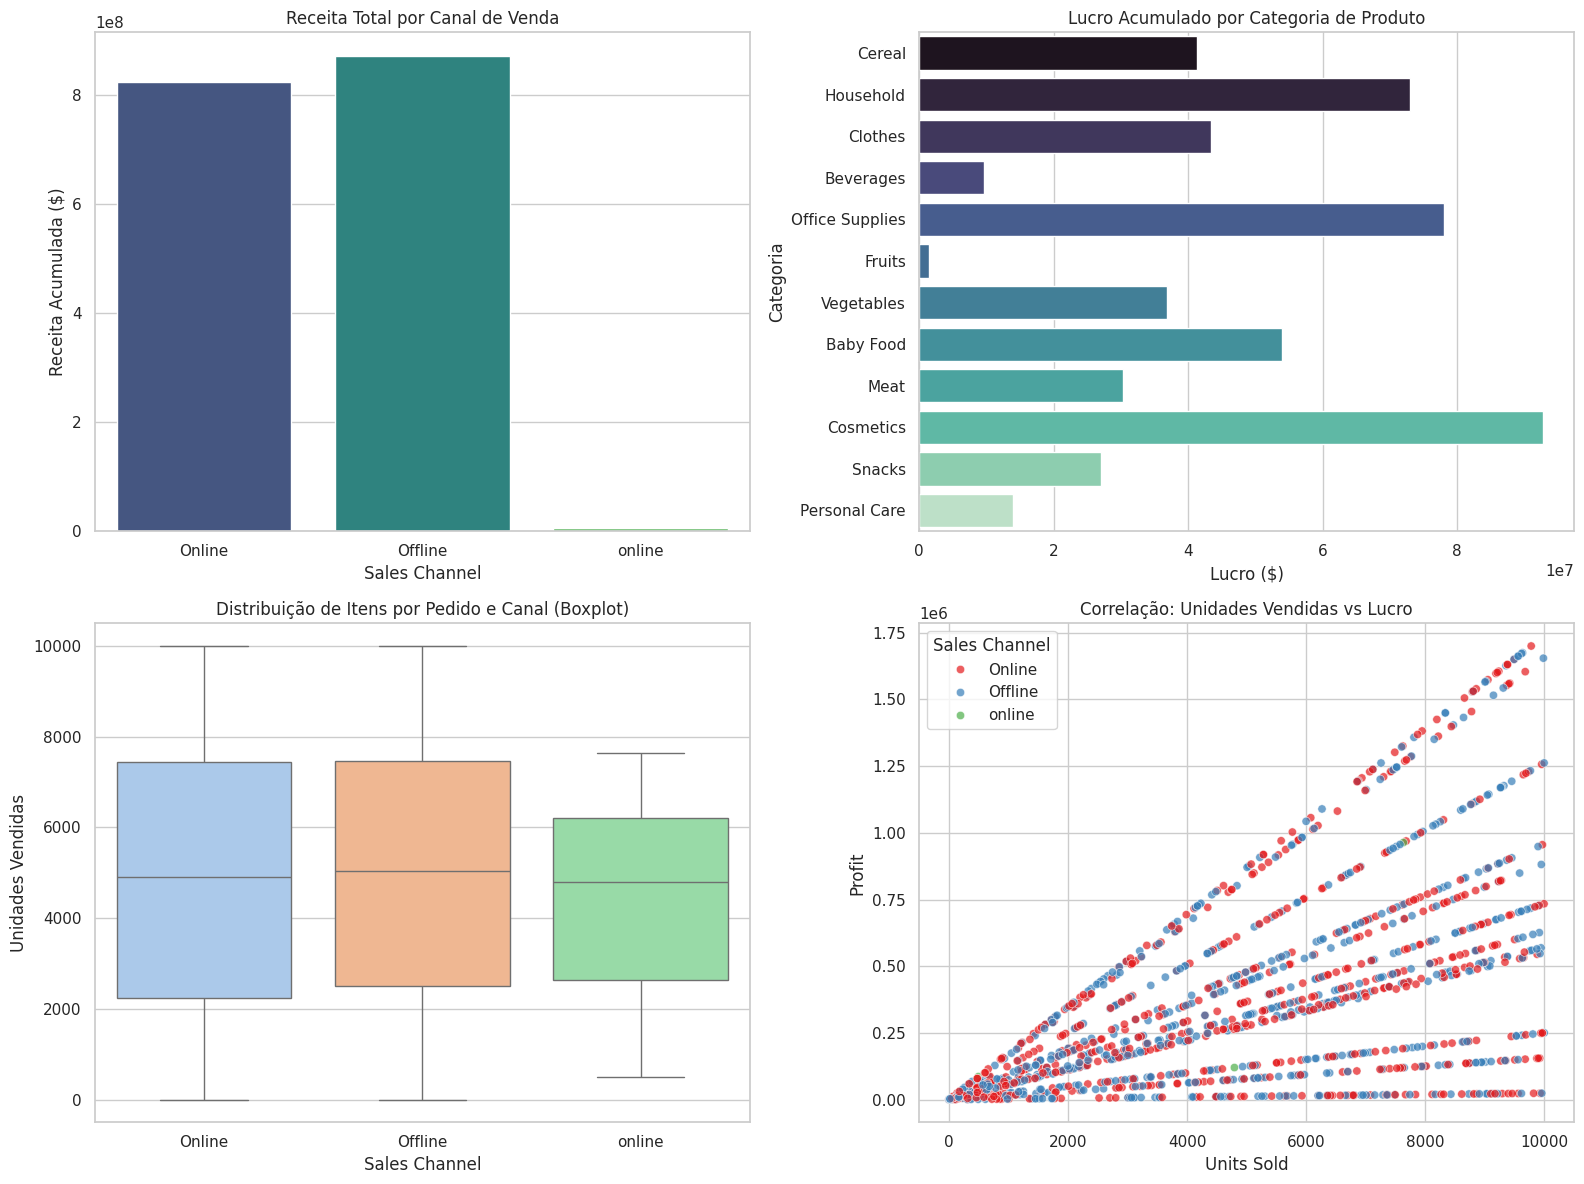

In [ ]:


sns.set_theme(style="whitegrid")

# Criando uma matriz de gráficos com o Seaborn/Matplotlib para analisar as principais distribuições de vendas e lucros
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Distribuição de Receita por Canal de Venda
sns.barplot(ax=axes[0, 0], x='Sales Channel', y='Revenue', data=df_final, estimator=sum, errorbar=None, palette='viridis', hue='Sales Channel', legend=False)
axes[0, 0].set_title('Receita Total por Canal de Venda')
axes[0, 0].set_ylabel('Receita Acumulada ($)')

# 2. Lucro Total por Categoria (Item Type)
sns.barplot(ax=axes[0, 1], x='Profit', y='item_type', data=df_final, estimator=sum, errorbar=None, palette='mako', hue='item_type', legend=False)
axes[0, 1].set_title('Lucro Acumulado por Categoria de Produto')
axes[0, 1].set_xlabel('Lucro ($)')
axes[0, 1].set_ylabel('Categoria')

# 3. Distribuição de Unidades Vendidas por Canal em Boxplot
sns.boxplot(ax=axes[1, 0], x='Sales Channel', y='Units Sold', data=df_final, palette='pastel', hue='Sales Channel', legend=False)
axes[1, 0].set_title('Distribuição de Itens por Pedido e Canal (Boxplot)')
axes[1, 0].set_ylabel('Unidades Vendidas')

# 4. Relação entre Unidades Vendidas e Lucro
sns.scatterplot(ax=axes[1, 1], x='Units Sold', y='Profit', hue='Sales Channel', data=df_final, palette='Set1', alpha=0.7)
axes[1, 1].set_title('Correlação: Unidades Vendidas vs Lucro')

plt.tight_layout()
plt.show()

### 3. Análise Detalhada de Vendas por Categoria, Geografia e Canal
Nesta seção, analisamos o desempenho geral decomposto pelas dimensões estratégicas da empresa.

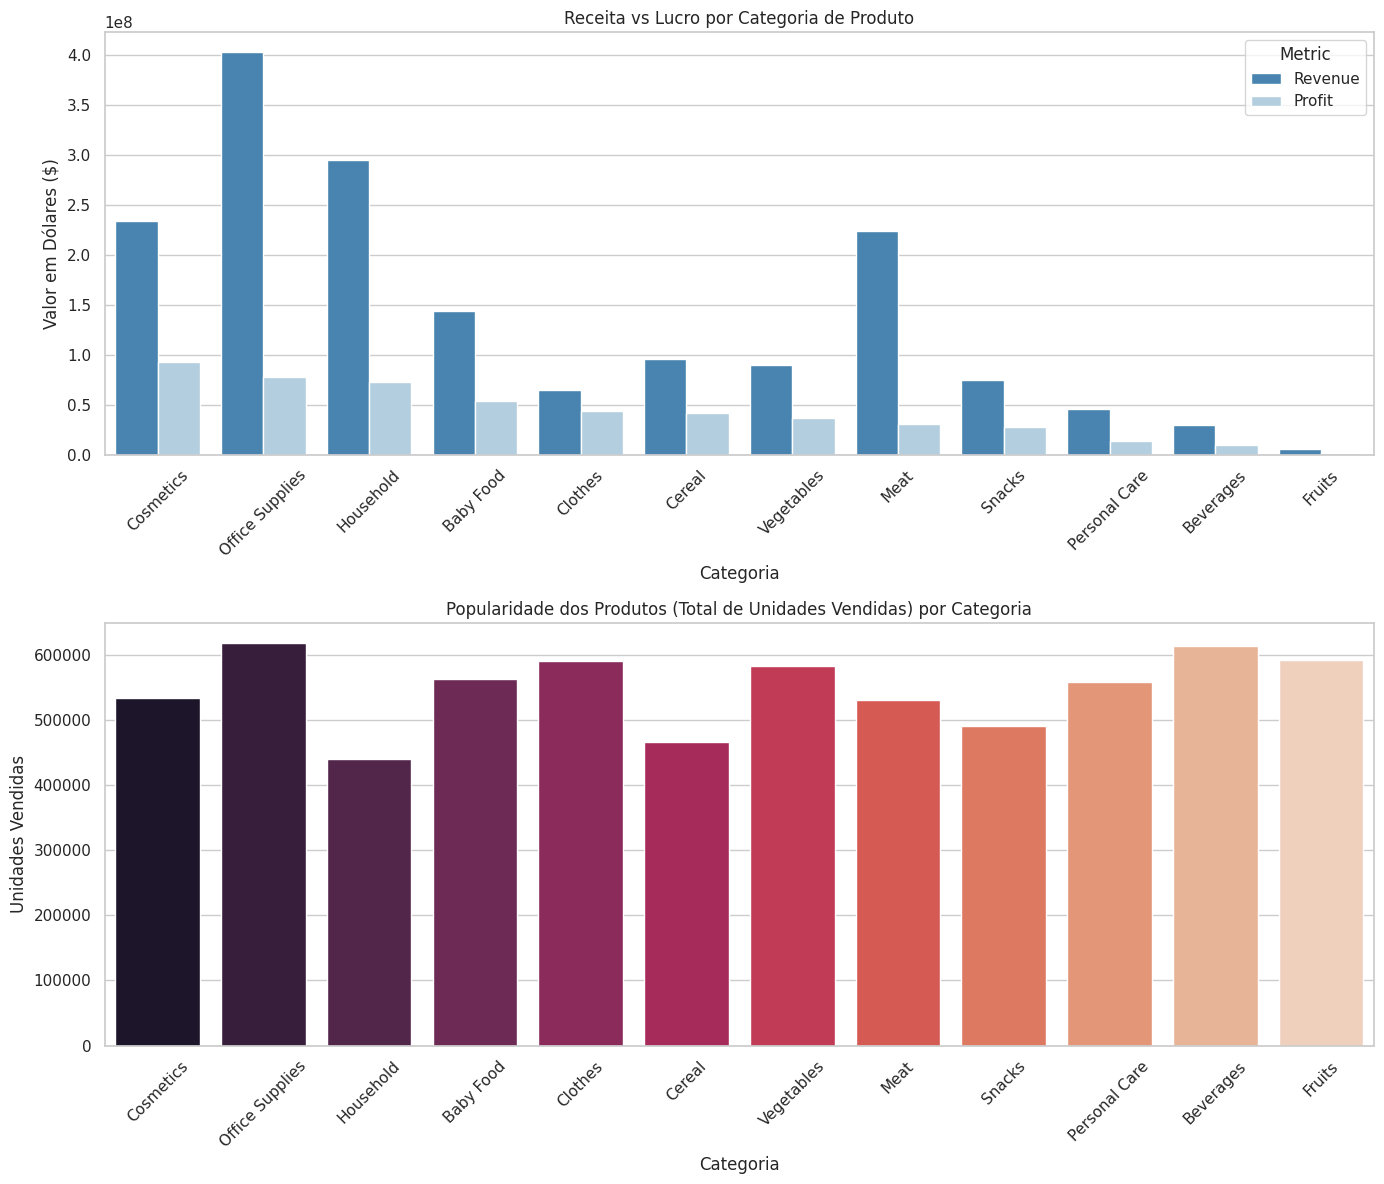

In [ ]:
# 3.1. Análise por Categoria de Produto


# Agrupando por categoria (item_type)
cat_analysis = df_final.groupby('item_type').agg(
    Revenue=('Revenue', 'sum'),
    Cost=('Cost', 'sum'),
    Profit=('Profit', 'sum'),
    Units_Sold=('Units Sold', 'sum')
).reset_index().sort_values(by='Profit', ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Gráfico de Lucro e Receita por Categoria
cat_melted = cat_analysis.melt(id_vars='item_type', value_vars=['Revenue', 'Profit'], var_name='Metric', value_name='Amount')
sns.barplot(ax=axes[0], x='item_type', y='Amount', hue='Metric', data=cat_melted, palette='Blues_r')
axes[0].set_title('Receita vs Lucro por Categoria de Produto')
axes[0].set_ylabel('Valor em Dólares ($)')
axes[0].set_xlabel('Categoria')
axes[0].tick_params(axis='x', rotation=45)

# Gráfico de Popularidade (Unidades Vendidas) por Categoria
sns.barplot(ax=axes[1], x='item_type', y='Units_Sold', data=cat_analysis, palette='rocket', hue='item_type', legend=False)
axes[1].set_title('Popularidade dos Produtos (Total de Unidades Vendidas) por Categoria')
axes[1].set_ylabel('Unidades Vendidas')
axes[1].set_xlabel('Categoria')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

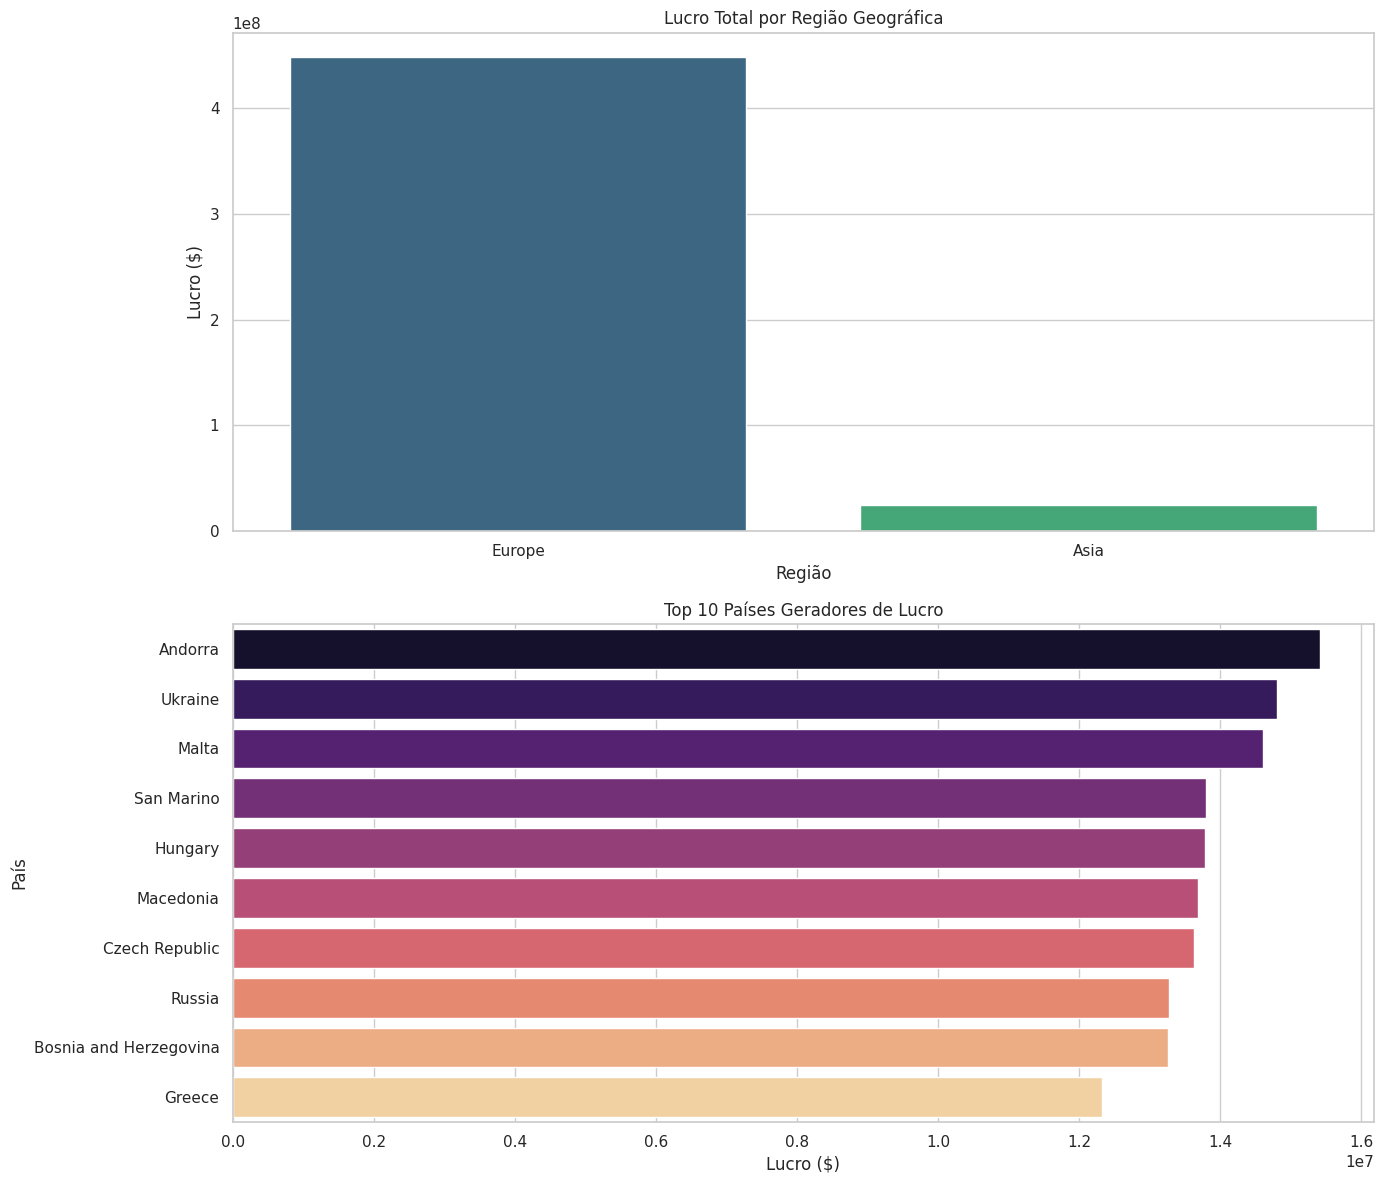

In [ ]:
# 3.2. Análise por Geografia (Regiões e Top Países)

# Agrupando por Região
region_analysis = df_final.groupby('region').agg(
    Revenue=('Revenue', 'sum'),
    Cost=('Cost', 'sum'),
    Profit=('Profit', 'sum'),
    Units_Sold=('Units Sold', 'sum')
).reset_index().sort_values(by='Profit', ascending=False)

# Agrupando por País (Top 10 por Lucro)
country_analysis = df_final.groupby('name').agg(
    Revenue=('Revenue', 'sum'),
    Profit=('Profit', 'sum'),
    Units_Sold=('Units Sold', 'sum')
).reset_index().sort_values(by='Profit', ascending=False).head(10)

fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Lucro por Região
sns.barplot(ax=axes[0], x='region', y='Profit', data=region_analysis, palette='viridis', hue='region', legend=False)
axes[0].set_title('Lucro Total por Região Geográfica')
axes[0].set_ylabel('Lucro ($)')
axes[0].set_xlabel('Região')

# Top 10 Países por Lucro
sns.barplot(ax=axes[1], x='Profit', y='name', data=country_analysis, palette='magma', hue='name', legend=False)
axes[1].set_title('Top 10 Países Geradores de Lucro')
axes[1].set_xlabel('Lucro ($)')
axes[1].set_ylabel('País')

plt.tight_layout()
plt.show()

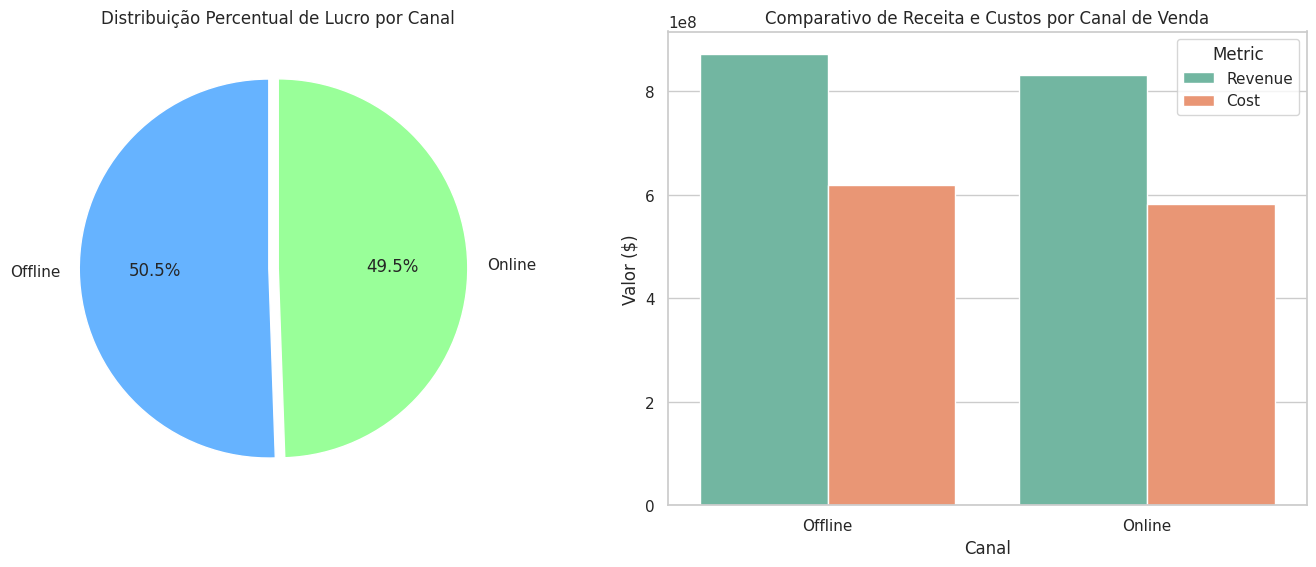

In [ ]:
# Corrigindo inconsistências de maiúsculas/minúsculas nos canais de venda
df_final['Sales Channel'] = df_final['Sales Channel'].astype(str).str.capitalize()

channel_analysis = df_final.groupby('Sales Channel').agg(
    Revenue=('Revenue', 'sum'),
    Cost=('Cost', 'sum'),
    Profit=('Profit', 'sum'),
    Units_Sold=('Units Sold', 'sum')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ax = axes.flatten()

# Gráfico de Setores (Pizza) para Lucro por Canal
ax[0].pie(channel_analysis['Profit'], labels=channel_analysis['Sales Channel'], autopct='%1.1f%%', colors=['#66b3ff','#99ff99'], startangle=90, explode=(0.05, 0))
ax[0].set_title('Distribuição Percentual de Lucro por Canal')

# Comparativo Receita vs Custos
channel_melted = channel_analysis.melt(id_vars='Sales Channel', value_vars=['Revenue', 'Cost'], var_name='Metric', value_name='Amount')
sns.barplot(ax=ax[1], x='Sales Channel', y='Amount', hue='Metric', data=channel_melted, palette='Set2')
ax[1].set_title('Comparativo de Receita e Custos por Canal de Venda')
ax[1].set_ylabel('Valor ($)')
ax[1].set_xlabel('Canal')

plt.tight_layout()
plt.show()

### 4. Análise do Intervalo de Tempo Entre Pedido e Envio
Nesta seção, calculamos o tempo de processamento/envio (`Ship Date` - `Order Date`) em dias e analisamos suas médias por categorias de produtos, regiões e países.

In [ ]:
# Calculando o tempo de envio em dias
df_final['Shipping Time (Days)'] = (df_final['Ship Date'] - df_final['Order Date']).dt.days

# Verificando estatísticas básicas do tempo de envio
print(df_final['Shipping Time (Days)'].describe())

count    1330.000000
mean       24.775940
std        14.577915
min         0.000000
25%        12.000000
50%        25.000000
75%        37.000000
max        50.000000
Name: Shipping Time (Days), dtype: float64


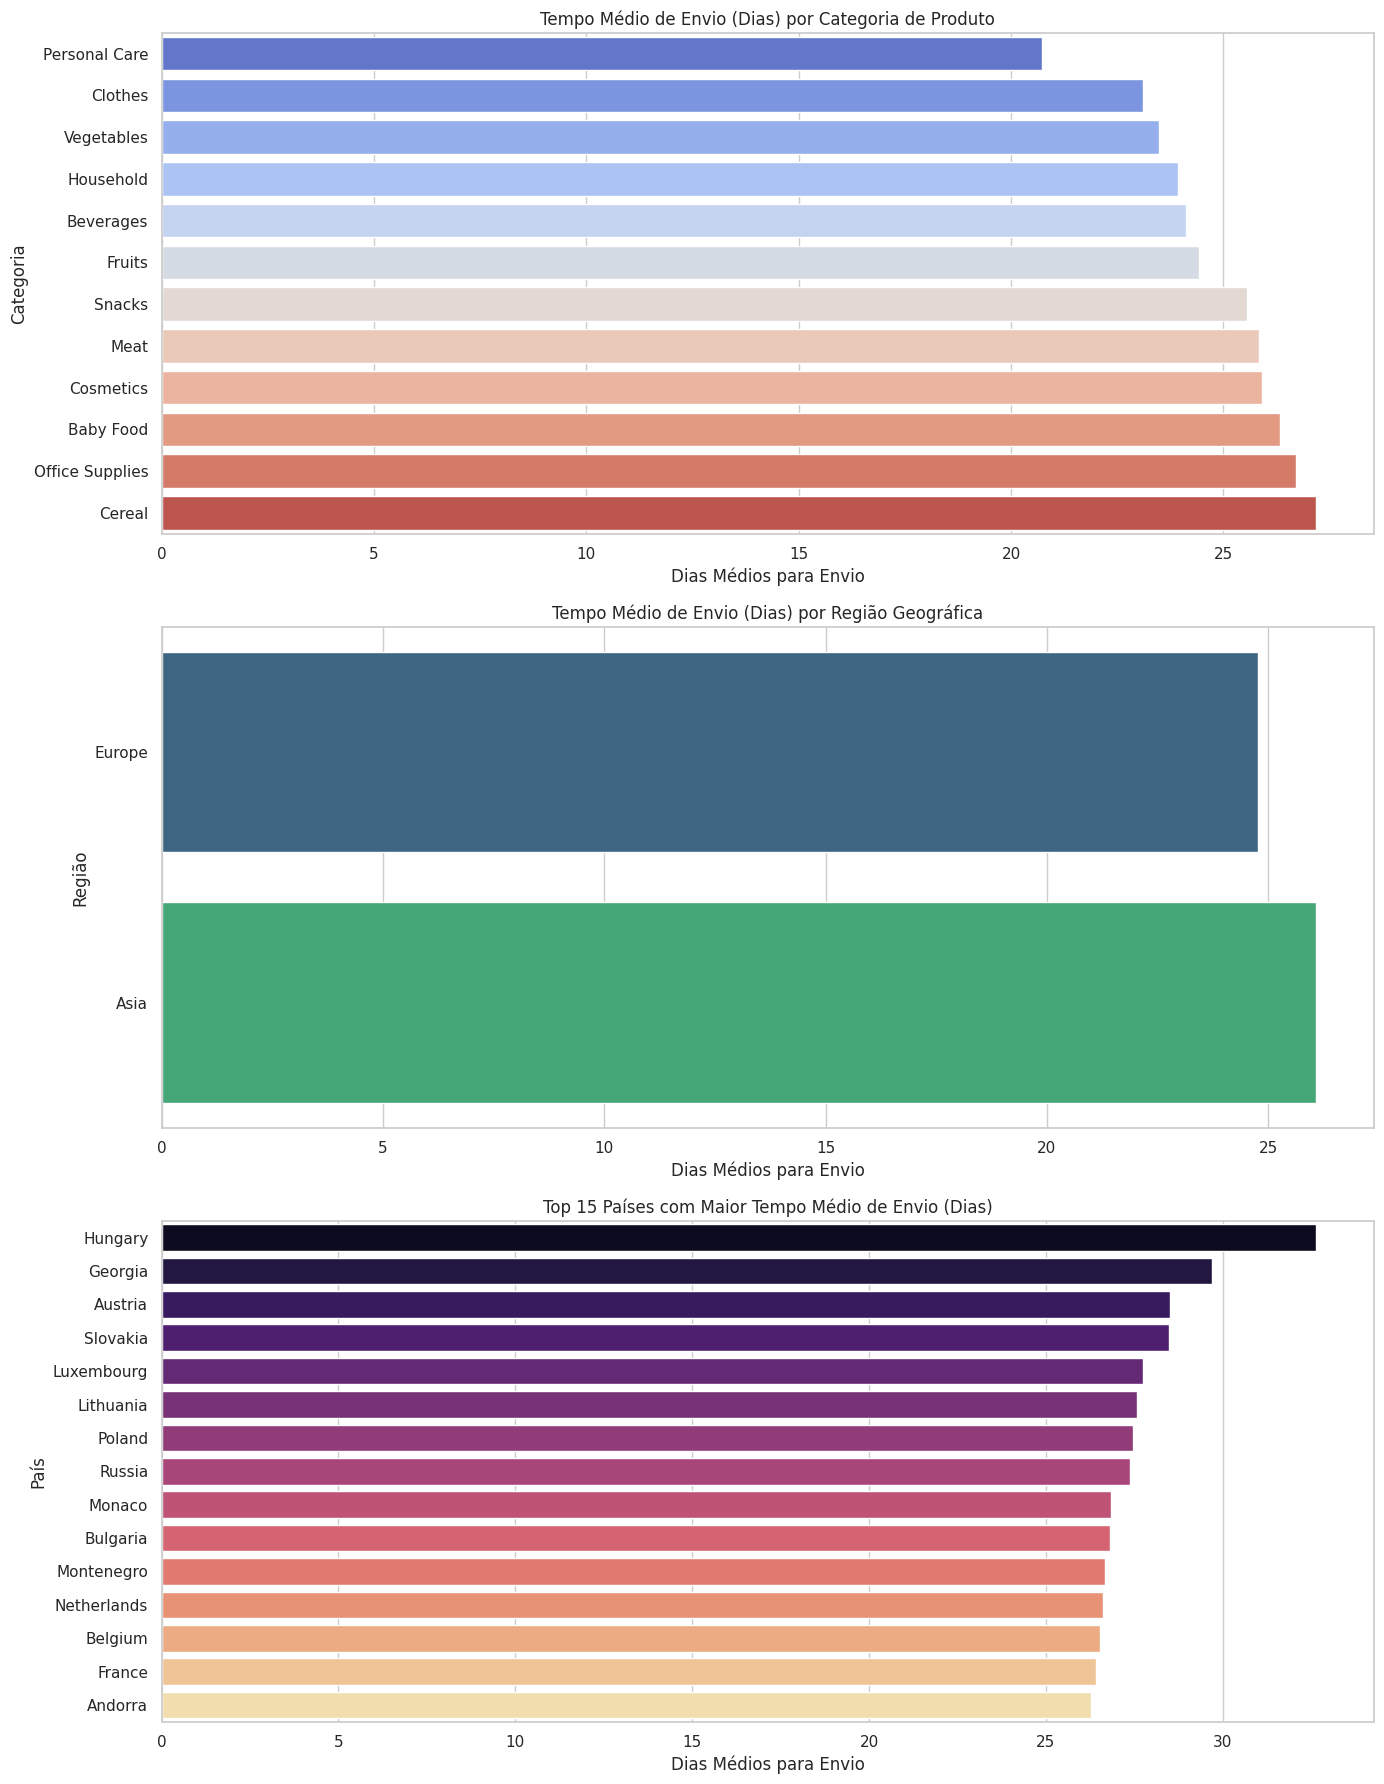

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 18))
ax = axes.flatten()

# 1. Tempo de envio por Categorias de Produtos
cat_shipping = df_final.groupby('item_type')['Shipping Time (Days)'].mean().reset_index().sort_values(by='Shipping Time (Days)')
sns.barplot(ax=ax[0], x='Shipping Time (Days)', y='item_type', data=cat_shipping, palette='coolwarm', hue='item_type', legend=False)
ax[0].set_title('Tempo Médio de Envio (Dias) por Categoria de Produto')
ax[0].set_xlabel('Dias Médios para Envio')
ax[0].set_ylabel('Categoria')

# 2. Tempo de envio por Regiões
region_shipping = df_final.groupby('region')['Shipping Time (Days)'].mean().reset_index().sort_values(by='Shipping Time (Days)')
sns.barplot(ax=ax[1], x='Shipping Time (Days)', y='region', data=region_shipping, palette='viridis', hue='region', legend=False)
ax[1].set_title('Tempo Médio de Envio (Dias) por Região Geográfica')
ax[1].set_xlabel('Dias Médios para Envio')
ax[1].set_ylabel('Região')

# 3. Tempo de envio por Países (Top 15 Países com maior tempo de envio)
country_shipping = df_final.groupby('name')['Shipping Time (Days)'].mean().reset_index().sort_values(by='Shipping Time (Days)', ascending=False).head(15)
sns.barplot(ax=ax[2], x='Shipping Time (Days)', y='name', data=country_shipping, palette='magma', hue='name', legend=False)
ax[2].set_title('Top 15 Países com Maior Tempo Médio de Envio (Dias)')
ax[2].set_xlabel('Dias Médios para Envio')
ax[2].set_ylabel('País')

plt.tight_layout()
plt.show()

### 5. Análise de Dependência: Lucro vs. Tempo de Envio
Vamos investigar se o tempo necessário para o envio (`Shipping Time (Days)`) tem impacto ou correlação com o lucro (`Profit`).

In [ ]:
# Calculando a correlação de Pearson entre o Tempo de Envio e o Lucro
correlation = df_final['Shipping Time (Days)'].corr(df_final['Profit'])
print(f"Coeficiente de correlação de Pearson entre Tempo de Envio e Lucro: {correlation:.4f}")

# Agrupando o lucro médio e mediano por cada dia de tempo de envio
shipping_profit_agg = df_final.groupby('Shipping Time (Days)').agg(
    Mean_Profit=('Profit', 'mean'),
    Median_Profit=('Profit', 'median'),
    Total_Profit=('Profit', 'sum'),
    Order_Count=('Order ID', 'count')
).reset_index()

Coeficiente de correlação de Pearson entre Tempo de Envio e Lucro: 0.0603


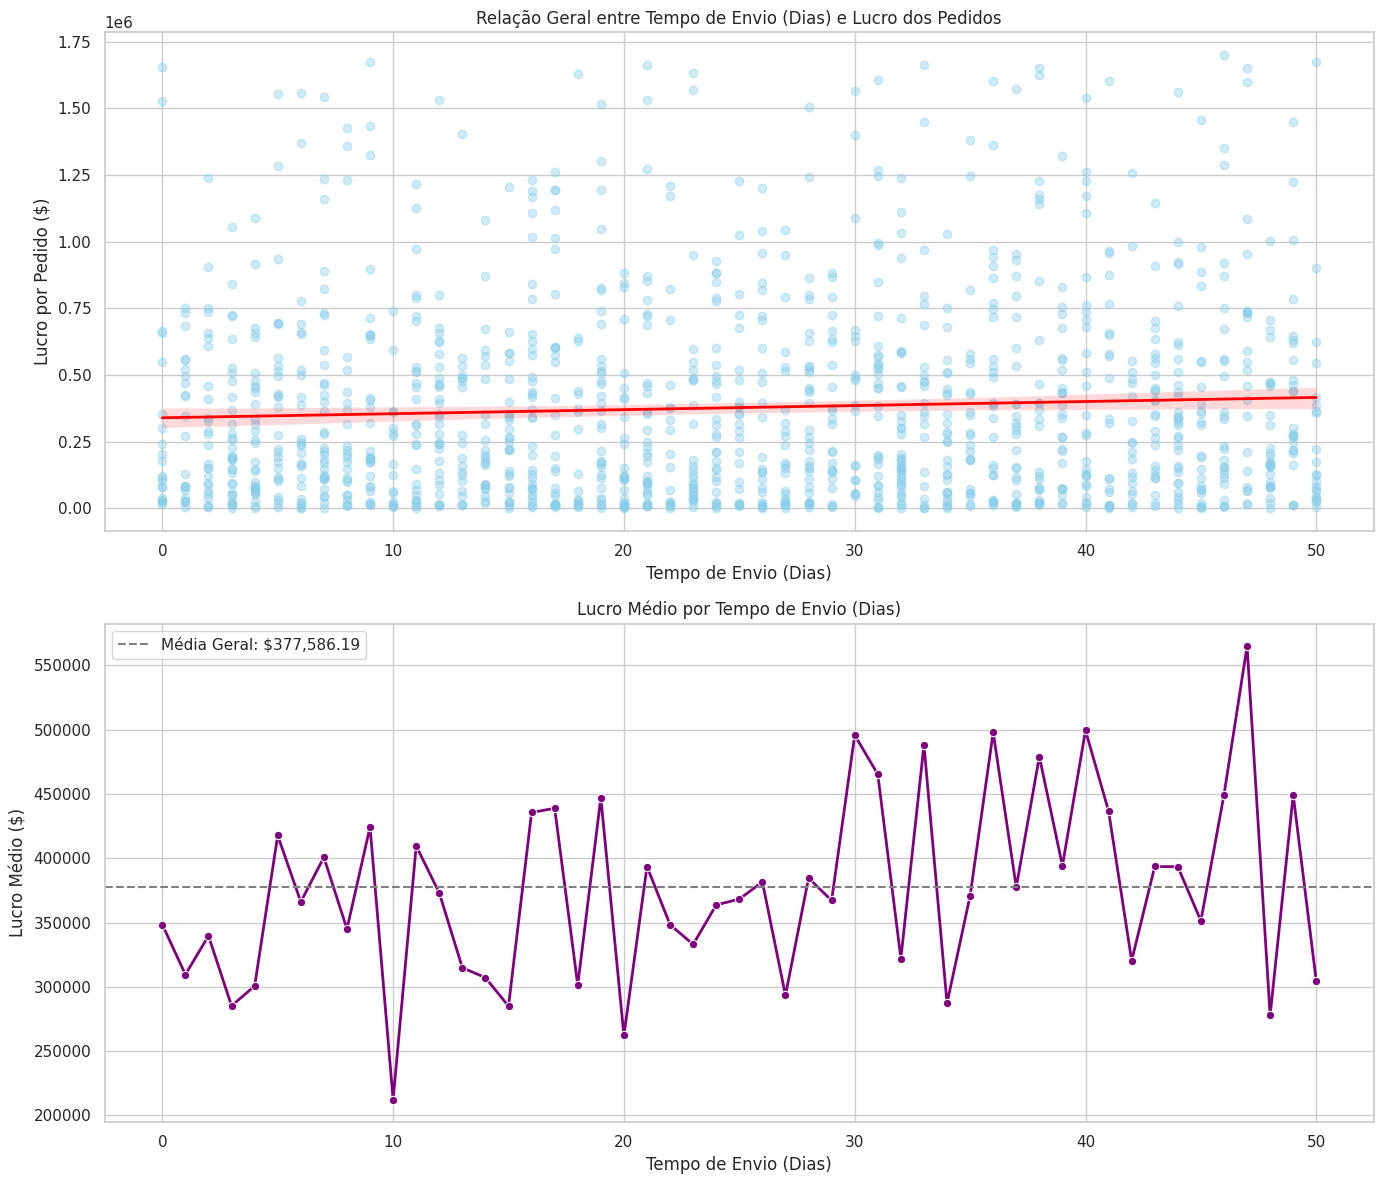

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 12))
ax = axes.flatten()

# 1. Gráfico de dispersão com linha de tendência (Regressão Linear) para analisar a tendência geral
sns.regplot(ax=ax[0], x='Shipping Time (Days)', y='Profit', data=df_final,
            scatter_kws={'alpha':0.4, 'color': 'skyblue'}, line_kws={'color': 'red', 'linewidth': 2})
ax[0].set_title('Relação Geral entre Tempo de Envio (Dias) e Lucro dos Pedidos')
ax[0].set_xlabel('Tempo de Envio (Dias)')
ax[0].set_ylabel('Lucro por Pedido ($)')

# 2. Lucro Médio por Dia de Envio para avaliar flutuações específicas
sns.lineplot(ax=ax[1], x='Shipping Time (Days)', y='Mean_Profit', data=shipping_profit_agg, marker='o', color='purple', linewidth=2)
ax[1].set_title('Lucro Médio por Tempo de Envio (Dias)')
ax[1].set_xlabel('Tempo de Envio (Dias)')
ax[1].set_ylabel('Lucro Médio ($)')
ax[1].axhline(df_final['Profit'].mean(), color='gray', linestyle='--', label=f'Média Geral: ${df_final["Profit"].mean():,.2f}')
ax[1].legend()

plt.tight_layout()
plt.show()

# 📋 RELATÓRIO : DINÂMICA DE VENDAS E ANÁLISE DE SAZONALIDADE

Este relatório apresenta a evolução temporal das vendas e investiga se determinados produtos possuem comportamentos sazonais baseados nos dias da semana.

## 📈 1. Dinâmica de Vendas ao Longo do Tempo
Vamos analisar o comportamento de vendas e faturamento agregados mensalmente para identificar tendências históricas.

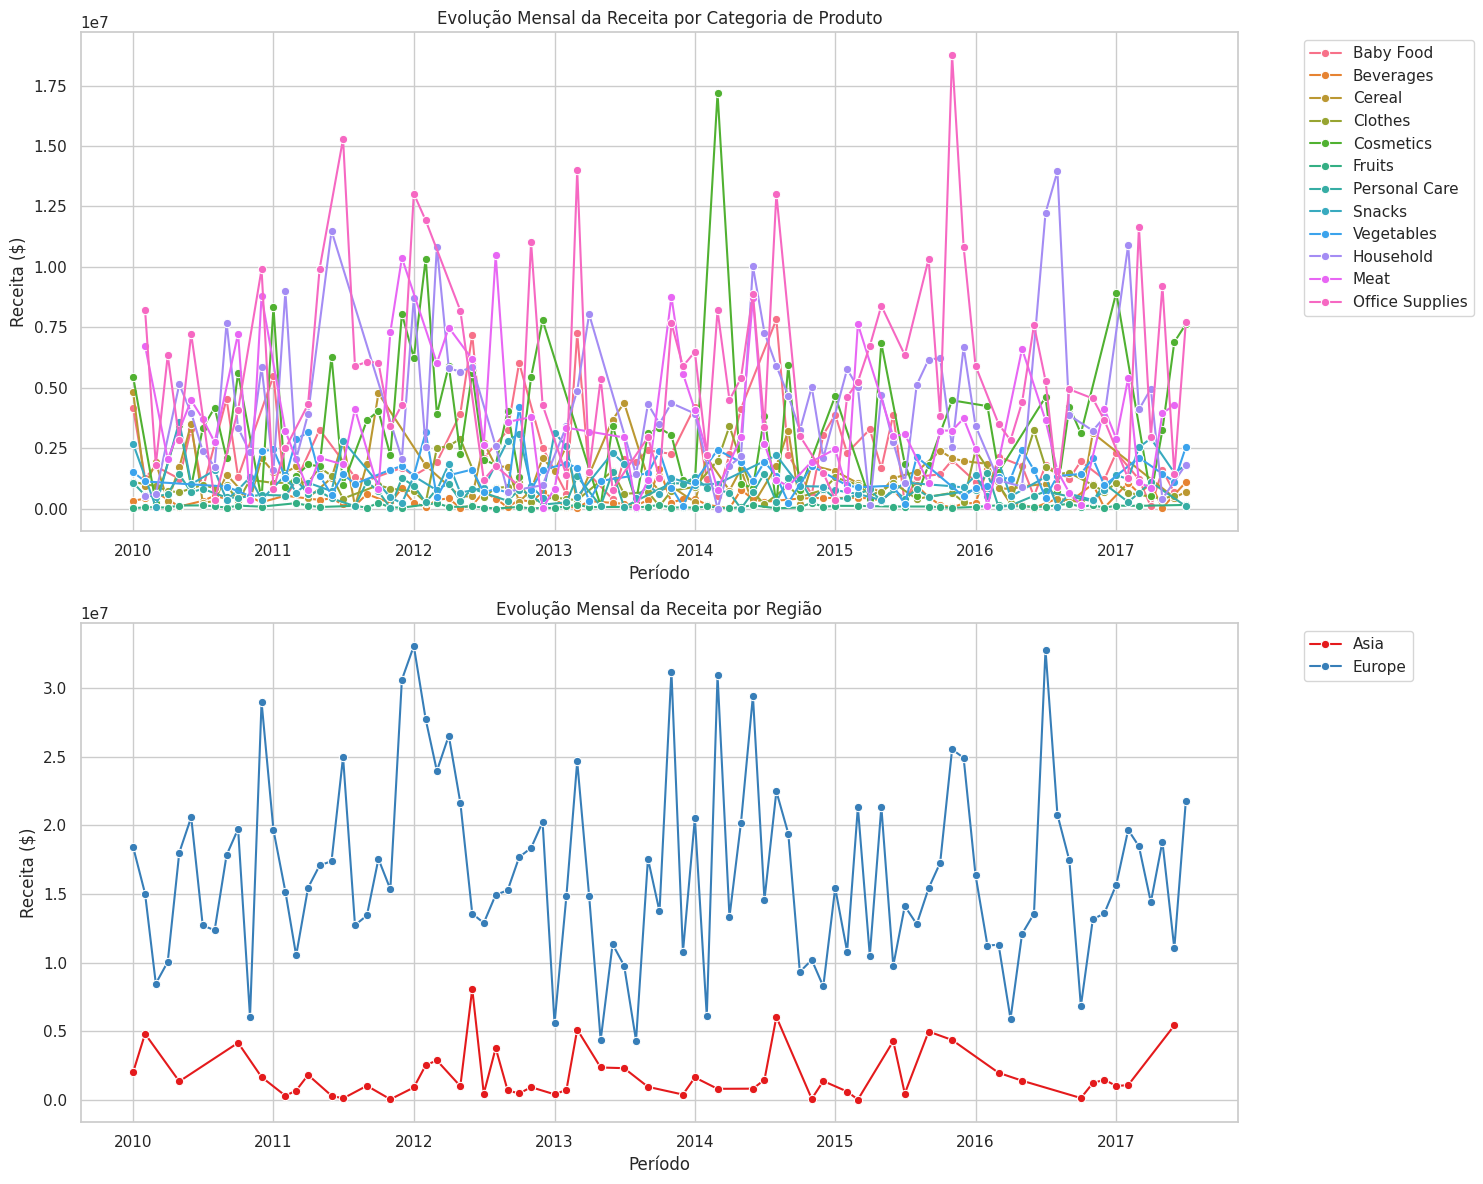

In [ ]:
# Extraindo o ano e mês para a análise de tendência temporal
df_final['Year_Month'] = df_final['Order Date'].dt.to_period('M')

# Agrupando faturamento ao longo do tempo por Categoria
time_cat = df_final.groupby(['Year_Month', 'item_type'])['Revenue'].sum().reset_index()
time_cat['Year_Month'] = time_cat['Year_Month'].dt.to_timestamp()

# Agrupando por Região ao longo do tempo
time_region = df_final.groupby(['Year_Month', 'region'])['Revenue'].sum().reset_index()
time_region['Year_Month'] = time_region['Year_Month'].dt.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(15, 12))

# Evolução por Categoria
sns.lineplot(ax=axes[0], data=time_cat, x='Year_Month', y='Revenue', hue='item_type', marker='o')
axes[0].set_title('Evolução Mensal da Receita por Categoria de Produto')
axes[0].set_xlabel('Período')
axes[0].set_ylabel('Receita ($)')
axes[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Evolução por Região
sns.lineplot(ax=axes[1], data=time_region, x='Year_Month', y='Revenue', hue='region', marker='o', palette='Set1')
axes[1].set_title('Evolução Mensal da Receita por Região')
axes[1].set_xlabel('Período')
axes[1].set_ylabel('Receita ($)')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

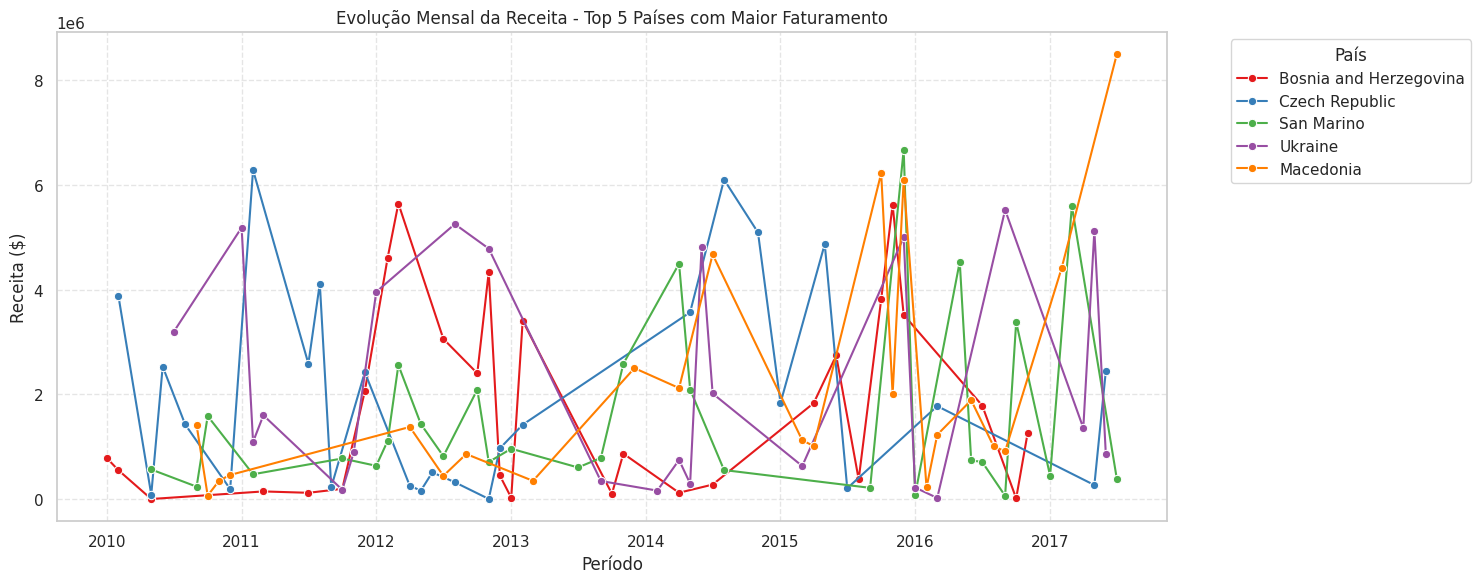

In [ ]:


# Agrupando por país ao longo do tempo (Ano/Mês)
time_country = df_final.groupby(['Year_Month', 'name'])['Revenue'].sum().reset_index()
time_country['Year_Month'] = time_country['Year_Month'].dt.to_timestamp()

# Identificando os 5 países com maior receita total para destacar no gráfico
top_countries = df_final.groupby('name')['Revenue'].sum().nlargest(5).index.tolist()

# Filtrando o histórico apenas para os top países
time_top_countries = time_country[time_country['name'].isin(top_countries)]

# Plotando a dinâmica de vendas (Receita) por país
plt.figure(figsize=(15, 6))
sns.lineplot(data=time_top_countries, x='Year_Month', y='Revenue', hue='name', marker='o', palette='Set1')

plt.title('Evolução Mensal da Receita - Top 5 Países com Maior Faturamento')
plt.xlabel('Período')
plt.ylabel('Receita ($)')
plt.legend(title='País', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 📌 Insights Rápidos: Dinâmica de Vendas (Top Países)

* **Alta Oscilação (Vendas Spot):** O faturamento é marcado por picos extremos e meses sem vendas. Isso indica um modelo focado em grandes contratos pontuais em vez de receita recorrente.
* **Falta de Sincronismo:** Os picos de vendas não coincidem entre os países, o que ajuda a equilibrar o faturamento global da empresa, mas dificulta a previsão local.
* **Recomendação de Melhoria:** Criar contratos de fornecimento programado (mensal/trimestral) com os grandes distribuidores destes países para suavizar os vales de receita e otimizar o estoque.

## 📅 2. Vendas por Dia da Semana e Sazonalidade
(sazonalidade semanal).

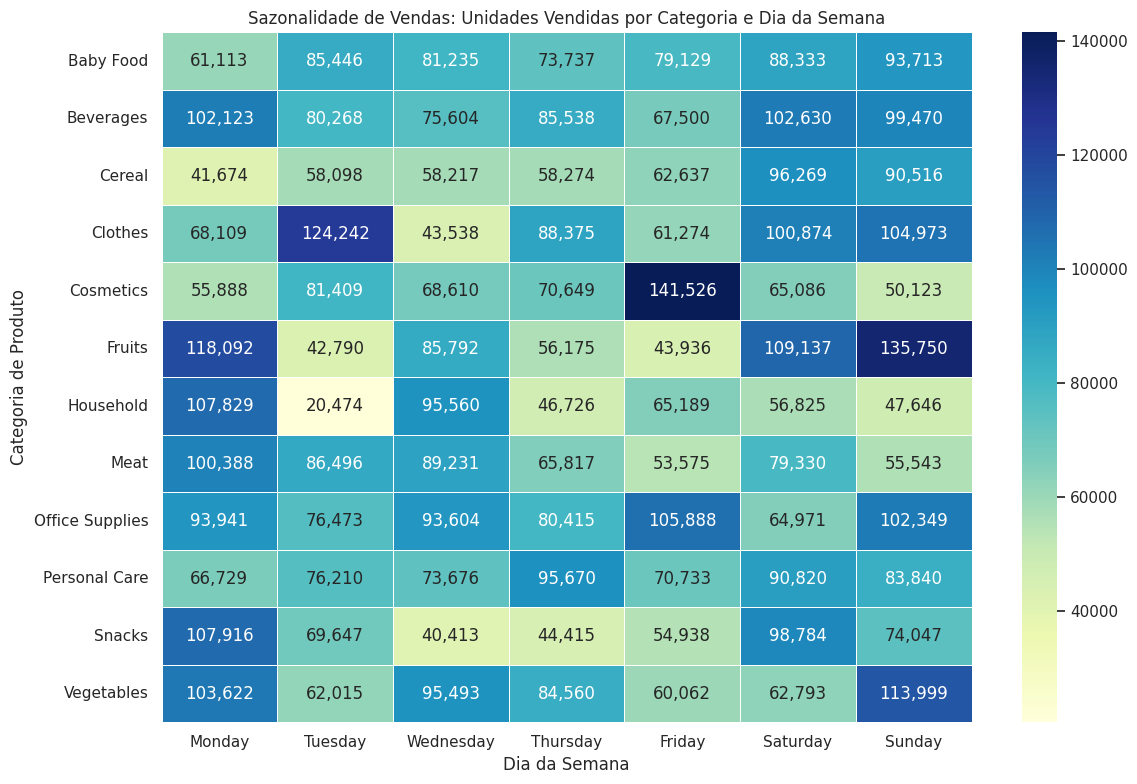

In [ ]:
# Determinando o nome do dia da semana a partir da data do pedido
df_final['Day_of_Week'] = df_final['Order Date'].dt.day_name()

# Ordenação lógica dos dias da semana
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Agrupando unidades vendidas por produto e dia da semana
weekday_sales = df_final.groupby(['Day_of_Week', 'item_type'])['Units Sold'].sum().reset_index()

# Pivotando para melhor visualização em um Heatmap de Sazonalidade
heatmap_data = weekday_sales.pivot(index='item_type', columns='Day_of_Week', values='Units Sold')[days_order]

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, fmt=",.0f", cmap="YlGnBu", linewidths=.5)
plt.title('Sazonalidade de Vendas: Unidades Vendidas por Categoria e Dia da Semana')
plt.xlabel('Dia da Semana')
plt.ylabel('Categoria de Produto')
plt.tight_layout()
plt.show()

## 🎯 3. Conclusões e Recomendações de Lógica de Negócios

Com base em todo o ecossistema de dados analisado, podemos extrair os seguintes direcionamentos estratégicos para maximizar a eficiência e a lucratividade da empresa:

### 1. Portfólio de Produtos e Maximização de Margem
* **Cosméticos, Office Supplies e Household** são os pilares de rentabilidade absoluta. Cosméticos lidera de forma isolada no lucro gerado (~$92.7M), apesar de não ser a categoria com maior volume de unidades físicas transacionadas.
* **Frutas e Bebidas** operam em mercados de alto giro de estoque, porém com margens unitárias muito estreitas.
* **Recomendação**: Adotar estratégias de cross-selling (venda cruzada), ofertando produtos de alta margem (ex: Cosméticos e Cuidados Pessoais) associados à compra de itens de alta recorrência e menor margem.

### 2. Logística de Envio vs. Rentabilidade
* O tempo médio geral para envio é de **24.7 dias** (com máximo chegando ao teto de 50 dias).
* A correlação entre o tempo de envio e o lucro gerado pelo pedido é de apenas **0.0603** (praticamente nula). Isso indica que **o tempo de processamento logístico não impacta diretamente o valor financeiro do pedido** e que clientes que compram lotes maiores ou de maior valor não recebem tratamento de priorização de frete.
* Países como **Hungria** (32.6 dias médios) e **Geórgia** (29.6 dias) representam gargalos críticos.
* **Recomendação**: Implementar acordos de SLA de entrega prioritária para mercados mais lucrativos (como Andorra e Ucrânia) e para pedidos que ultrapassem um patamar mínimo de receita, otimizando o fluxo logístico onde há maior impacto ao cliente de alto valor.

### 3. Sazonalidade de Vendas e Planejamento de Inventário
* O heatmap de sazonalidade semanal revela um comportamento estável por categoria de produto, porém com picos específicos em determinados dias para itens de escritório e de alimentação básica.
* **Recomendação**: Utilizar os dados de sazonalidade semanal para calibrar o reabastecimento de estoques locais, minimizando custos de armazenagem e garantindo disponibilidade de produto no pico correto da demanda.

### 4. Concentração Geográfica e Expansão
* O mercado Europeu domina amplamente os resultados em comparação com a região asiática.
* **Recomendação**: Fortalecer a presença nos 10 principais países geradores de resultado (liderados por Andorra, Ucrânia e Malta) com campanhas de fidelidade exclusivas, enquanto se estuda barreiras de entrada e canais de distribuição mais eficientes para expandir a operação no mercado asiático.